<a href="https://colab.research.google.com/github/chawlaniharika23/Fraud_Detection_Research/blob/main/notebooks/04_improved_base_model_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 04 — Base Model Training and Evaluation

## Financial Fraud Detection: IEEE-CIS

### Objective
Train, compare, and save the six base classifiers used by the subsequent ensemble-learning notebook. All models are fitted on the training partition and evaluated on the validation partition. The independent test partition is deliberately not loaded or evaluated here.

### Models
1. Logistic Regression (LR)
2. Decision Tree (DT)
3. Random Forest (RF)
4. Gradient Boosting Classifier (GBT)
5. Calibrated Linear Support Vector Machine (SVM)
6. Multi-Layer Perceptron (MLP)

### Improvements over the original notebook
- Adds imbalance-aware metrics: PR-AUC, MCC, balanced accuracy, false-positive rate, and Brier score.
- Uses `class_weight` where supported and balanced sample weights for Gradient Boosting.
- Calibrates LinearSVC using cross-validation on training data only.
- Saves validation probabilities separately for the stacking notebook.
- Saves a complete model comparison table and run metadata.
- Uses validation data for comparison only; it does not touch the held-out test partition.
- Adds checks for feature/label alignment, sparse matrix shape, finite probabilities, and model output validity.

**Important:** Validation metrics are model-selection results, not final research-paper test results. Do not report them as held-out test performance.

## 1. Imports and reproducibility

In [1]:
import os
import gc
import json
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import scipy
import sklearn

from scipy.sparse import load_npz
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    confusion_matrix,
    brier_score_loss
)
from sklearn.utils.class_weight import compute_sample_weight
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.5f}")

RANDOM_STATE = 42
DEFAULT_THRESHOLD = 0.50

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)

NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3
scikit-learn: 1.6.1


## 2. Mount Google Drive and configure paths

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
BASE_DIR = Path("/content/drive/MyDrive/fraud-detection-research")
PROCESSED_DIR = BASE_DIR / "data" / "processed"
RECOVERY_DIR = PROCESSED_DIR / "recovered"

MODEL_DIR = BASE_DIR / "results" / "base_models"
PREDICTION_DIR = MODEL_DIR / "validation_predictions"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_MATRIX_PATH = RECOVERY_DIR / "ieee_X_train_selected_100.npz"
VAL_MATRIX_PATH = RECOVERY_DIR / "ieee_X_validation_selected_100.npz"
TRAIN_TARGET_PATH = PROCESSED_DIR / "ieee_y_train.parquet"
VAL_TARGET_PATH = PROCESSED_DIR / "ieee_y_validation.parquet"

required_paths = [
    TRAIN_MATRIX_PATH, VAL_MATRIX_PATH,
    TRAIN_TARGET_PATH, VAL_TARGET_PATH
]
missing_paths = [str(path) for path in required_paths if not path.exists()]
if missing_paths:
    raise FileNotFoundError(
        "Required Notebook 03 outputs are missing:\n"
        + "\n".join(missing_paths)
        + "\nRun Notebook 03 successfully before running Notebook 04."
    )

print("Model directory:", MODEL_DIR)
print("Validation prediction directory:", PREDICTION_DIR)

Model directory: /content/drive/MyDrive/fraud-detection-research/results/base_models
Validation prediction directory: /content/drive/MyDrive/fraud-detection-research/results/base_models/validation_predictions


## 3. Load selected features and labels

In [4]:
X_train = load_npz(TRAIN_MATRIX_PATH).tocsr().astype(np.float32)
X_val = load_npz(VAL_MATRIX_PATH).tocsr().astype(np.float32)

y_train = pd.read_parquet(TRAIN_TARGET_PATH)["isFraud"].to_numpy(dtype=np.int8)
y_val = pd.read_parquet(VAL_TARGET_PATH)["isFraud"].to_numpy(dtype=np.int8)

if X_train.shape[0] != len(y_train):
    raise ValueError("Training matrix and labels have different row counts.")
if X_val.shape[0] != len(y_val):
    raise ValueError("Validation matrix and labels have different row counts.")
if X_train.shape[1] != X_val.shape[1]:
    raise ValueError("Training and validation feature counts do not match.")
if X_train.shape[1] != 100:
    raise ValueError(
        f"Expected 100 selected features from Notebook 03; got {X_train.shape[1]}."
    )
if not np.isin(y_train, [0, 1]).all() or not np.isin(y_val, [0, 1]).all():
    raise ValueError("Target labels must be binary 0/1.")

print("Training matrix:", X_train.shape, X_train.dtype)
print("Validation matrix:", X_val.shape, X_val.dtype)
print(f"Training fraud rate:   {y_train.mean() * 100:.4f}%")
print(f"Validation fraud rate: {y_val.mean() * 100:.4f}%")
print("Training class counts:", np.bincount(y_train))
print("Validation class counts:", np.bincount(y_val))

Training matrix: (413378, 100) float32
Validation matrix: (88581, 100) float32
Training fraud rate:   3.5169%
Validation fraud rate: 3.4341%
Training class counts: [398840  14538]
Validation class counts: [85539  3042]


## 4. Define evaluation helper

The default threshold is 0.50 for consistent baseline comparison. PR-AUC and ROC-AUC evaluate ranking quality across thresholds, while precision, recall, F1, MCC, balanced accuracy, and false-positive rate describe predictions at the chosen threshold.

In [5]:
def evaluate_probabilities(y_true, probabilities, threshold=DEFAULT_THRESHOLD):
    probabilities = np.asarray(probabilities, dtype=np.float64).reshape(-1)

    if len(probabilities) != len(y_true):
        raise ValueError("Prediction and target lengths do not match.")
    if not np.isfinite(probabilities).all():
        raise ValueError("Predicted probabilities contain NaN or infinity.")

    probabilities = np.clip(probabilities, 0.0, 1.0)
    predictions = (probabilities >= threshold).astype(np.int8)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "Threshold": float(threshold),
        "Accuracy": accuracy_score(y_true, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1": f1_score(y_true, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(y_true, probabilities),
        "MCC": matthews_corrcoef(y_true, predictions),
        "FPR": fp / (fp + tn) if (fp + tn) else 0.0,
        "Brier_Score": brier_score_loss(y_true, probabilities),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)
    }


print("Evaluation helper defined.")

Evaluation helper defined.


## 5. Configure the six base classifiers

The selected feature matrix contains 100 columns. The configurations below are practical starting points rather than globally optimized hyperparameters. Any further tuning should use training/validation data only and should be documented in the final paper.

In [6]:
models = {
    "LR": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        solver="lbfgs",
        C=1.0,
        random_state=RANDOM_STATE
    ),

    "DT": DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "RF": RandomForestClassifier(
        n_estimators=120,
        max_depth=14,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "GBT": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_samples_leaf=10,
        subsample=0.8,
        random_state=RANDOM_STATE
    ),

    "SVM": LinearSVC(
        C=0.5,
        class_weight="balanced",
        max_iter=3000,
        random_state=RANDOM_STATE
    ),

    "MLP": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=1e-4,
        batch_size=256,
        learning_rate_init=1e-3,
        max_iter=60,
        early_stopping=True,
        validation_fraction=0.10,
        n_iter_no_change=8,
        random_state=RANDOM_STATE
    )
}

print("Configured models:", list(models.keys()))

Configured models: ['LR', 'DT', 'RF', 'GBT', 'SVM', 'MLP']


## 6. Train models and generate validation probabilities

All six models are trained using the training partition. Gradient Boosting receives balanced sample weights because its estimator does not expose a `class_weight` parameter. LinearSVC is wrapped in probability calibration; its calibration folds are drawn only from the training partition.

The validation partition is used only after fitting to generate predictions and calculate comparative metrics.

In [7]:
results = []
validation_probabilities = {}
saved_models = {}
training_diagnostics = {}

for model_name, base_model in models.items():
    print(f"\n{'=' * 18} Training {model_name} {'=' * 18}")
    start_time = time.time()

    if model_name == "SVM":
        # Calibrate the decision scores using training-only cross-validation.
        evaluation_model = CalibratedClassifierCV(
            estimator=clone(base_model),
            method="sigmoid",
            cv=3,
            n_jobs=-1
        )
        evaluation_model.fit(X_train, y_train)

    elif model_name == "GBT":
        # Explicitly compensate for class imbalance during boosting.
        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_train
        )
        evaluation_model = clone(base_model)
        evaluation_model.fit(
            X_train,
            y_train,
            sample_weight=sample_weights
        )
        del sample_weights

    else:
        evaluation_model = clone(base_model)
        evaluation_model.fit(X_train, y_train)

    fit_seconds = time.time() - start_time

    # Every saved model exposes calibrated/class probabilities.
    probabilities = evaluation_model.predict_proba(X_val)[:, 1]
    metrics = evaluate_probabilities(
        y_val,
        probabilities,
        threshold=DEFAULT_THRESHOLD
    )

    prediction_start = time.time()
    # Measure a separate validation prediction pass for inference latency.
    probabilities = evaluation_model.predict_proba(X_val)[:, 1]
    prediction_seconds = time.time() - prediction_start

    metrics["Model"] = model_name
    metrics["Training_Time_Seconds"] = fit_seconds
    metrics["Validation_Prediction_Time_Seconds"] = prediction_seconds
    metrics["Prediction_Time_Per_1000_Rows_ms"] = (
        prediction_seconds / max(len(y_val), 1) * 1000 * 1000
    )
    results.append(metrics)

    validation_probabilities[model_name] = probabilities.astype(np.float32)
    saved_models[model_name] = evaluation_model

    model_path = MODEL_DIR / f"{model_name}_model.joblib"
    joblib.dump(evaluation_model, model_path, compress=3)

    print(
        f"{model_name}: PR-AUC={metrics['PR_AUC']:.5f} | "
        f"F1={metrics['F1']:.5f} | Recall={metrics['Recall']:.5f} | "
        f"fit={fit_seconds:.1f}s"
    )

    del probabilities
    gc.collect()

results_df = pd.DataFrame(results).set_index("Model")
results_df = results_df.sort_values(
    by="PR_AUC",
    ascending=False
).reset_index()

results_df.to_csv(MODEL_DIR / "base_model_results.csv", index=False)
print("\nBase-model training and validation evaluation completed.")
display(results_df.round(5))


================== Training LR ==================
LR: PR-AUC=0.36113 | F1=0.15099 | Recall=0.77449 | fit=51.0s

================== Training DT ==================
DT: PR-AUC=0.35762 | F1=0.25041 | Recall=0.62393 | fit=63.2s

================== Training RF ==================
RF: PR-AUC=0.45900 | F1=0.36239 | Recall=0.58974 | fit=827.3s

================== Training GBT ==================
GBT: PR-AUC=0.38359 | F1=0.22493 | Recall=0.72814 | fit=284.8s

================== Training SVM ==================
SVM: PR-AUC=0.34868 | F1=0.19394 | Recall=0.10947 | fit=162.3s

================== Training MLP ==================
MLP: PR-AUC=0.44934 | F1=0.45198 | Recall=0.35503 | fit=238.4s

Base-model training and validation evaluation completed.


,Model,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,MCC,FPR,Brier_Score,TN,FP,FN,TP,Training_Time_Seconds,Validation_Prediction_Time_Seconds,Prediction_Time_Per_1000_Rows_ms
0,RF,0.50000,0.92873,0.76527,0.26155,0.58974,0.36239,0.87713,0.45900,0.36147,0.05921,0.07773,80474,5065,1248,1794,827.33296,1.94249,21.92897
1,MLP,0.50000,0.97043,0.67367,0.62176,0.35503,0.45198,0.85801,0.44934,0.45620,0.00768,0.02557,84882,657,1962,1080,238.35226,0.16863,1.90371
2,GBT,0.50000,0.82767,0.77968,0.13301,0.72814,0.22493,0.85645,0.38359,0.26071,0.16879,0.13822,71101,14438,827,2215,284.81144,0.18244,2.05954
3,LR,0.50000,0.70090,0.73638,0.08365,0.77449,0.15099,0.82777,0.36113,0.18488,0.30172,0.19269,59730,25809,686,2356,51.00110,0.05209,0.58809
4,DT,0.50000,0.87172,0.75223,0.15664,0.62393,0.25041,0.78158,0.35762,0.26734,0.11947,0.11683,75320,10219,1144,1898,63.24175,0.02022,0.22826
5,SVM,0.50000,0.96875,0.55439,0.84949,0.10947,0.19394,0.82164,0.34868,0.29844,0.00069,0.02757,85480,59,2709,333,162.25080,0.12437,1.40401


## 7. Save validation probabilities for ensemble learning

In [8]:
# Save one probability vector per model. Notebook 05 can load this file
# without having to regenerate predictions from all six fitted models.
probability_output = {
    f"{name}_validation_probability": values
    for name, values in validation_probabilities.items()
}
np.savez_compressed(
    PREDICTION_DIR / "base_model_validation_probabilities.npz",
    **probability_output
)

# Save validation labels alongside the probability file for alignment checks.
np.save(
    PREDICTION_DIR / "validation_labels.npy",
    y_val
)

# Save the model order explicitly; do not rely on dictionary ordering later.
model_order = list(validation_probabilities.keys())
with open(MODEL_DIR / "base_model_order.json", "w") as file:
    json.dump(model_order, file, indent=2)

print("Saved validation probability vectors for:", model_order)
print("Prediction artifact:", PREDICTION_DIR / "base_model_validation_probabilities.npz")

Saved validation probability vectors for: ['LR', 'DT', 'RF', 'GBT', 'SVM', 'MLP']
Prediction artifact: /content/drive/MyDrive/fraud-detection-research/results/base_models/validation_predictions/base_model_validation_probabilities.npz


## 8. Threshold sensitivity on validation data

This section is diagnostic only. It shows how each model's precision/recall/F1 trade-off changes with the classification threshold. If a later notebook selects thresholds for the ensemble, that selection must use validation data and the test set must remain untouched.

Do not interpret the best threshold in this table as a final test result.

In [9]:
threshold_rows = []
threshold_grid = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

for model_name, probabilities in validation_probabilities.items():
    for threshold in threshold_grid:
        row = evaluate_probabilities(
            y_val,
            probabilities,
            threshold=threshold
        )
        threshold_rows.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": row["Precision"],
            "Recall": row["Recall"],
            "F1": row["F1"],
            "MCC": row["MCC"],
            "FPR": row["FPR"]
        })

threshold_df = pd.DataFrame(threshold_rows)
threshold_df.to_csv(
    MODEL_DIR / "base_model_threshold_analysis.csv",
    index=False
)

best_f1_rows = (
    threshold_df.sort_values(["Model", "F1"], ascending=[True, False])
    .groupby("Model", as_index=False)
    .first()
    .sort_values("F1", ascending=False)
)
print("Best validation F1 threshold per model (diagnostic):")
display(best_f1_rows.round(5))

Best validation F1 threshold per model (diagnostic):


,Model,Threshold,Precision,Recall,F1,MCC,FPR
3,MLP,0.30000,0.52936,0.41782,0.46702,0.45373,0.01321
4,RF,0.70000,0.55719,0.37311,0.44694,0.44049,0.01054
0,DT,0.90000,0.43129,0.39513,0.41242,0.39287,0.01853
1,GBT,0.80000,0.52960,0.32347,0.40163,0.39808,0.01022
2,LR,0.90000,0.48737,0.31723,0.38431,0.37617,0.01187
5,SVM,0.10000,0.29950,0.43162,0.35362,0.33225,0.03590


## 9. Visualize model comparison

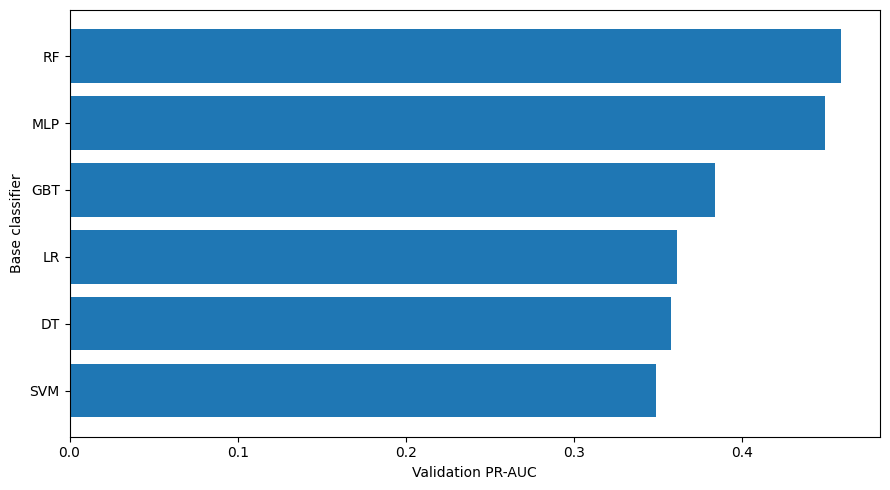

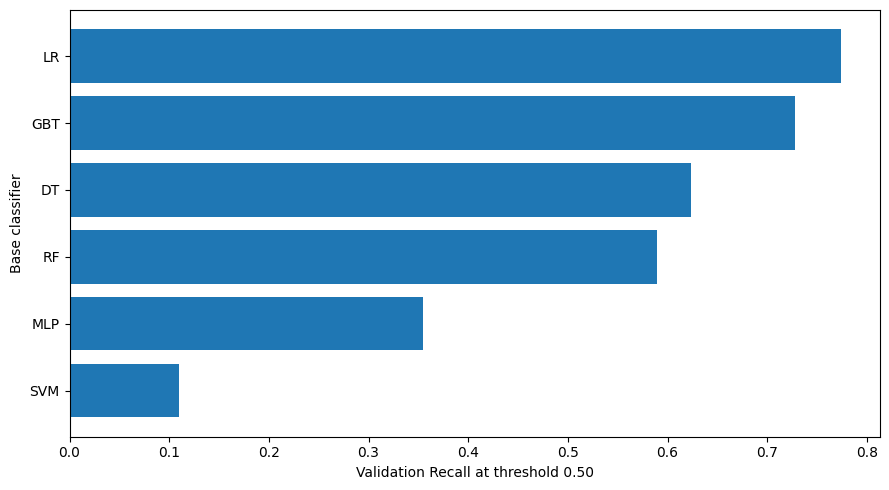

In [10]:
import matplotlib.pyplot as plt

plot_df = results_df.sort_values("PR_AUC", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(plot_df["Model"], plot_df["PR_AUC"])
plt.xlabel("Validation PR-AUC")
plt.ylabel("Base classifier")
plt.tight_layout()
plt.show()

plot_df = results_df.sort_values("Recall", ascending=True)

plt.figure(figsize=(9, 5))
plt.barh(plot_df["Model"], plot_df["Recall"])
plt.xlabel(f"Validation Recall at threshold {DEFAULT_THRESHOLD:.2f}")
plt.ylabel("Base classifier")
plt.tight_layout()
plt.show()

## 10. Final artifact and compatibility checks

The following files are consumed by the subsequent ensemble notebook:
- `results/base_models/LR_model.joblib`
- `results/base_models/DT_model.joblib`
- `results/base_models/RF_model.joblib`
- `results/base_models/GBT_model.joblib`
- `results/base_models/SVM_model.joblib`
- `results/base_models/MLP_model.joblib`
- `results/base_models/validation_predictions/base_model_validation_probabilities.npz`
- `results/base_models/validation_predictions/validation_labels.npy`
- `results/base_models/base_model_results.csv`
- `results/base_models/base_model_order.json`

The selected feature matrices and labels are not modified.

In [11]:
# Verify model files and saved validation predictions.
expected_model_files = [
    MODEL_DIR / f"{name}_model.joblib" for name in model_order
]
missing_models = [str(path) for path in expected_model_files if not path.exists()]
if missing_models:
    raise FileNotFoundError("Some model files were not saved:\n" + "\n".join(missing_models))

saved_probabilities = np.load(
    PREDICTION_DIR / "base_model_validation_probabilities.npz"
)
saved_labels = np.load(PREDICTION_DIR / "validation_labels.npy")

assert len(saved_labels) == X_val.shape[0]
for name in model_order:
    key = f"{name}_validation_probability"
    assert key in saved_probabilities.files
    assert len(saved_probabilities[key]) == len(y_val)
    assert np.isfinite(saved_probabilities[key]).all()

print("Saved models:", len(expected_model_files))
print("Saved probability vectors:", len(model_order))
print("Validation labels:", len(saved_labels))
print("All output checks passed.")

run_manifest = {
    "dataset": "IEEE-CIS",
    "feature_selection": "top 100 features from Notebook 03",
    "models": model_order,
    "random_state": RANDOM_STATE,
    "default_threshold": DEFAULT_THRESHOLD,
    "training_rows": int(X_train.shape[0]),
    "validation_rows": int(X_val.shape[0]),
    "selected_feature_count": int(X_train.shape[1]),
    "metrics": [
        "Accuracy", "Balanced_Accuracy", "Precision", "Recall", "F1",
        "ROC_AUC", "PR_AUC", "MCC", "FPR", "Brier_Score"
    ],
    "test_partition_used": False
}
with open(MODEL_DIR / "base_model_run_manifest.json", "w") as file:
    json.dump(run_manifest, file, indent=2)

print("\nNotebook 04 completed.")
print("Next: Notebook 05 — ensemble / dynamic stacking.")

Saved models: 6
Saved probability vectors: 6
Validation labels: 88581
All output checks passed.

Notebook 04 completed.
Next: Notebook 05 — ensemble / dynamic stacking.
